## 0. Importing libraries

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import copy

## 1. Loading dataset

In [2]:
data = fetch_california_housing()

In [3]:
data

{'data': array([[   8.3252    ,   41.        ,    6.98412698, ...,    2.55555556,
           37.88      , -122.23      ],
        [   8.3014    ,   21.        ,    6.23813708, ...,    2.10984183,
           37.86      , -122.22      ],
        [   7.2574    ,   52.        ,    8.28813559, ...,    2.80225989,
           37.85      , -122.24      ],
        ...,
        [   1.7       ,   17.        ,    5.20554273, ...,    2.3256351 ,
           39.43      , -121.22      ],
        [   1.8672    ,   18.        ,    5.32951289, ...,    2.12320917,
           39.43      , -121.32      ],
        [   2.3886    ,   16.        ,    5.25471698, ...,    2.61698113,
           39.37      , -121.24      ]], shape=(20640, 8)),
 'target': array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894], shape=(20640,)),
 'frame': None,
 'target_names': ['MedHouseVal'],
 'feature_names': ['MedInc',
  'HouseAge',
  'AveRooms',
  'AveBedrms',
  'Population',
  'AveOccup',
  'Latitude',
  'Longitude'],
 'DESCR': 

In [4]:
x, y = data.data, data.target

In [5]:
print(f'x: {type(x)}, x shape: {x.shape}')
print(f'y: {type(y)}, y shape: {y.shape}')

x: <class 'numpy.ndarray'>, x shape: (20640, 8)
y: <class 'numpy.ndarray'>, y shape: (20640,)


In [6]:
print(f'x: {x[0]}\ny: {y[0]}')

x: [   8.3252       41.            6.98412698    1.02380952  322.
    2.55555556   37.88       -122.23      ]
y: 4.526


## 2. Data preprocessing

Check for null and infinite values in x and y

In [7]:
invalid_x_values = np.any(~np.isfinite(x))
invalid_y_values = np.any(~np.isfinite(y))
print(f'x has invalid values: {invalid_x_values}')
print(f'y has invalid values: {invalid_y_values}')

x has invalid values: False
y has invalid values: False


In [8]:
assert np.issubdtype(x.dtype, np.number), "x must contain numerical data"
assert np.issubdtype(y.dtype, np.number), "y must contain numerical data"

Train-Test split:

In [9]:
x_train, x_temp, y_train, y_temp = train_test_split(x, y, train_size=0.6, random_state=42, shuffle=True)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, train_size=0.5, random_state=42, shuffle=True)

Normalization:

In [10]:
x_scaler = MinMaxScaler()
y_scaler = MinMaxScaler()

In [11]:
x_train = x_scaler.fit_transform(x_train)
x_val = x_scaler.transform(x_val)
x_test = x_scaler.transform(x_test)

y_train = y_scaler.fit_transform(y_train.reshape(-1, 1))
y_val = y_scaler.transform(y_val.reshape(-1, 1))
y_test = y_scaler.transform(y_test.reshape(-1, 1))

Convert data to Pytorch tensors:

In [12]:
torch.manual_seed(42)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
x_train = torch.tensor(x_train, device=device, dtype=torch.float32)
x_val = torch.tensor(x_val, device=device, dtype=torch.float32)
x_test = torch.tensor(x_test, device=device, dtype=torch.float32)

y_train = torch.tensor(y_train, device=device, dtype=torch.float32)
y_val = torch.tensor(y_val, device=device, dtype=torch.float32)
y_test = torch.tensor(y_test, device=device, dtype=torch.float32)

## 3. Build the model

In [13]:
input_dim = x_train.shape[-1]
print('x shape: ', x_train.shape)
print('input_dim: ', input_dim)

x shape:  torch.Size([12384, 8])
input_dim:  8


In [14]:
output_dim = y_train.shape[-1]
print('y shape: ', y_train.shape)
print('output_dim: ', output_dim)

y shape:  torch.Size([12384, 1])
output_dim:  1


In [15]:
model = nn.Sequential(
    nn.Linear(input_dim, 24),
    nn.ReLU(),
    nn.Linear(24, 12),
    nn.ReLU(),
    nn.Linear(12, 6),
    nn.ReLU(),
    nn.Linear(6, output_dim)
).to(device)

Defining parameters:

In [16]:
lr = 0.001
epochs = 100
batch_size = 32

In [17]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

In [18]:
batches = torch.arange(0, len(x_train), batch_size)
batches[0:5]

tensor([  0,  32,  64,  96, 128])

## 4.Training Loop

In [19]:
training_loss_history = []
validation_loss_history = []
best_loss = np.inf
best_epoch = 0
best_weights = None

for epoch in range(1, epochs + 1):
    model.train()
    epoch_train_loss = 0
    for batch in batches:
        x_batch = x_train[batch:batch + batch_size]
        y_batch = y_train[batch:batch + batch_size]
        
        y_pred = model(x_batch)
        loss = criterion(y_pred, y_batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        epoch_train_loss += loss.item() * len(x_batch)
    epoch_train_loss /= len(x_train)
    training_loss_history.append(epoch_train_loss)

    model.eval()
    with torch.inference_mode():
        y_pred_val = model(x_val)
        val_loss = criterion(y_pred_val, y_val).item()
    validation_loss_history.append(val_loss)

    if best_loss > val_loss:
        best_loss = val_loss
        best_epoch = epoch
        best_weights = copy.deepcopy(model.state_dict())

    if epoch % 10 == 0:
        print(f'Epoch: [{epoch}/{epochs}] |'
              f'train loss: {epoch_train_loss:.4f} |'
              f'validation loss: {val_loss:.4f}'
             )
print("Training complete")
print(f"Best Epoch: {best_epoch}")
print(f"Best Validation Loss: {best_loss:.4f}")

Epoch: [10/100] |train loss: 0.0200 |validation loss: 0.0211
Epoch: [20/100] |train loss: 0.0191 |validation loss: 0.0203
Epoch: [30/100] |train loss: 0.0184 |validation loss: 0.0197
Epoch: [40/100] |train loss: 0.0178 |validation loss: 0.0192
Epoch: [50/100] |train loss: 0.0171 |validation loss: 0.0183
Epoch: [60/100] |train loss: 0.0166 |validation loss: 0.0178
Epoch: [70/100] |train loss: 0.0163 |validation loss: 0.0174
Epoch: [80/100] |train loss: 0.0158 |validation loss: 0.0168
Epoch: [90/100] |train loss: 0.0154 |validation loss: 0.0163
Epoch: [100/100] |train loss: 0.0151 |validation loss: 0.0159
Training complete
Best Epoch: 100
Best Validation Loss: 0.0159


## 5.Testing the model

In [20]:
model.load_state_dict(best_weights)
model.eval()
with torch.inference_mode():
    y_pred_test = model(x_test)
    test_loss = criterion(y_pred_test, y_test).item()
print(f'Best epoch: {best_epoch}')
print(f'Best validation MSE: {best_loss:.4f}')
print(f'Test MSE(Normalized): {test_loss:.4f}')   

Best epoch: 100
Best validation MSE: 0.0159
Test MSE(Normalized): 0.0169


Convert tensors back to numpy arrays:

In [21]:
y_test_np = y_test.cpu().numpy()
y_pred_test_np = y_pred_test.cpu().numpy()

Inverse transform(back to original form):

In [22]:
y_test_original = y_scaler.inverse_transform(y_test_np)
y_pred_original = y_scaler.inverse_transform(y_pred_test_np)

In [23]:
test_mse = mean_squared_error(y_test_original, y_pred_original)
test_rmse = np.sqrt(test_mse)
test_mae = mean_absolute_error(y_test_original, y_pred_original)
test_r2 = r2_score(y_test_original, y_pred_original)
print('=====Test Results (Original scale)=====')
print(f'MSE: {test_mse:.4f}')
print(f"RMSE: {test_rmse:.4f}")
print(f"MAE:  {test_mae:.4f}")
print(f"R2 Score: {test_r2:.4f}")

=====Test Results (Original scale)=====
MSE: 0.3971
RMSE: 0.6302
MAE:  0.4174
R2 Score: 0.7104


## 6. Visualizing

Plot training and validation loss:

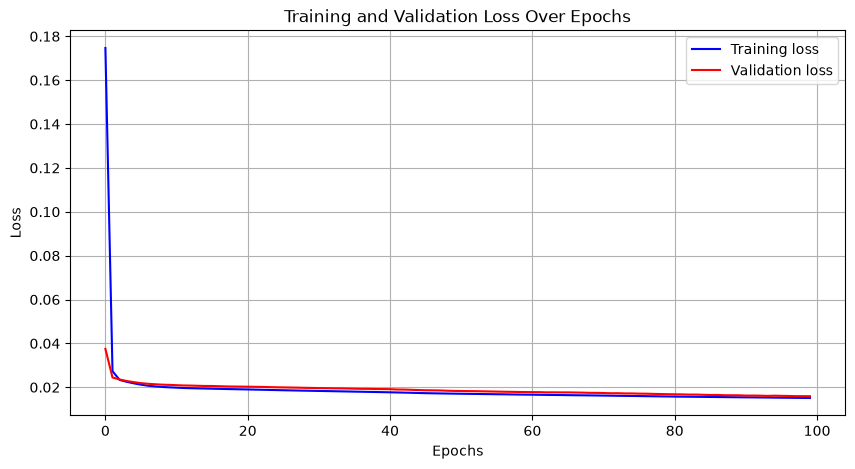

In [24]:
plt.figure(figsize=(10, 5))
plt.plot(training_loss_history, label = 'Training loss', color = 'blue')
plt.plot(validation_loss_history, label = 'Validation loss', color = 'red')
plt.title('Training and Validation Loss Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

Plot actual vs predicted:

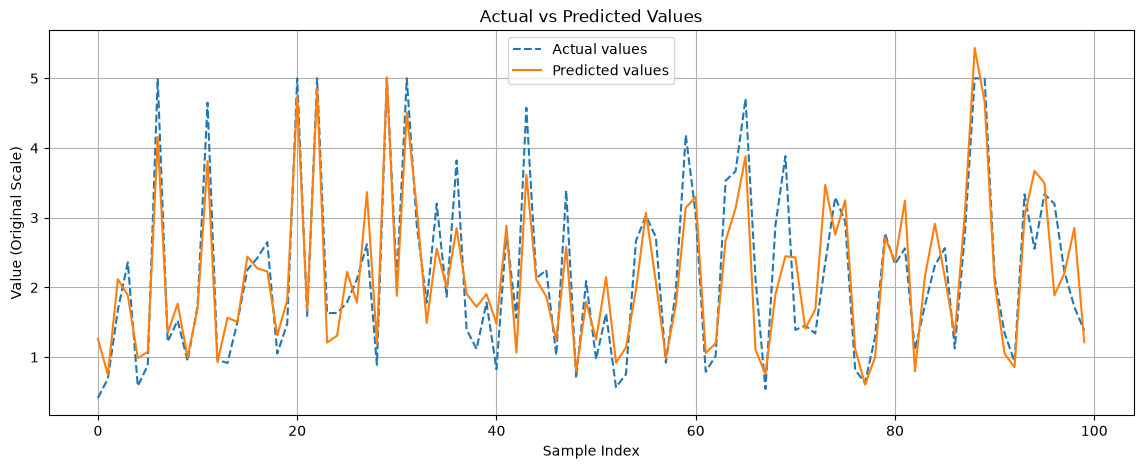

In [25]:
plt.figure(figsize=(14, 5))
plt.plot(y_test_original[:100].flatten(), label = 'Actual values', linestyle = '--')
plt.plot(y_pred_original[:100].flatten(), label = 'Predicted values', linestyle = '-')
plt.title('Actual vs Predicted Values')
plt.xlabel('Sample Index')
plt.ylabel('Value (Original Scale)')
plt.legend()
plt.grid()
plt.show()